### <font color = "gold"> Import les librairies requises

In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
# Supprimer les warnings
import warnings
warnings.filterwarnings('ignore')

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### <font color = "gold"> Importer et lire les données

In [4]:
# Importer les données
df = pd.read_csv('/content/sample_data/wheat_seeds_dataset.csv')


**Nous avons ici des données de graines de blé. Chaque graine de blé est caractérisée par 7 variables morphologiques (issues de l'étude morphologique de chaque graine).**

In [5]:
# Afficher les données
df.head()


,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [6]:
# Dimension des données
df.shape

(199, 7)

In [7]:
# Infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   area A                   199 non-null    float64
 1   perimeter                199 non-null    float64
 2   compactness              199 non-null    float64
 3   length of kernel         199 non-null    float64
 4   width of kernel          199 non-null    float64
 5   asymmetry coefficient    199 non-null    float64
 6   length of kernel groove  199 non-null    float64
dtypes: float64(7)
memory usage: 11.0 KB


In [8]:
# Décrire les données
df.describe()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
count,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,14.918744,14.595829,0.870811,5.643151,3.265533,3.699217,5.420653
std,2.919976,1.310445,0.023320,0.443593,0.378322,1.471102,0.492718
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000
25%,12.330000,13.470000,0.857100,5.267000,2.954500,2.570000,5.046000
50%,14.430000,14.370000,0.873400,5.541000,3.245000,3.631000,5.228000
75%,17.455000,15.805000,0.886800,6.002000,3.564500,4.799000,5.879000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.315000,6.550000


In [9]:
# Renommer les index
df.index = ['Graine' + str(i + 1) for i in range(len(df))]
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
Graine1,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
Graine2,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
Graine3,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
Graine4,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
Graine5,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [10]:
# Matrice des données
x = df.values
x[:5]

array([[15.26  , 14.84  ,  0.871 ,  5.763 ,  3.312 ,  2.221 ,  5.22  ],
       [14.88  , 14.57  ,  0.8811,  5.554 ,  3.333 ,  1.018 ,  4.956 ],
       [14.29  , 14.09  ,  0.905 ,  5.291 ,  3.337 ,  2.699 ,  4.825 ],
       [13.84  , 13.94  ,  0.8955,  5.324 ,  3.379 ,  2.259 ,  4.805 ],
       [16.14  , 14.99  ,  0.9034,  5.658 ,  3.562 ,  1.355 ,  5.175 ]])

In [11]:
# Importer Normalizer
from sklearn.preprocessing import Normalizer
# Instantier le normaliseur
scaler = Normalizer()
# Normaliser les données
x = scaler.fit_transform(df)
x[:5]

array([[0.66271789, 0.64447795, 0.03782617, 0.25027806, 0.14383497,
        0.09645455, 0.22669642],
       [0.66410726, 0.65027169, 0.03932425, 0.24787982, 0.14875467,
        0.04543422, 0.22119056],
       [0.65688362, 0.64769001, 0.0416011 , 0.24321702, 0.15339543,
        0.1240678 , 0.2217959 ],
       [0.64909686, 0.65378687, 0.04199901, 0.24969593, 0.15847531,
        0.10594724, 0.2253548 ],
       [0.68244585, 0.63382053, 0.03819836, 0.23923659, 0.15061166,
        0.05729332, 0.21881396]])

#### <font color = "gold"> Appliquer une ACP

In [12]:
from matplotlib.pyplot import draw_if_interactive
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca=PCA(n_components=2)
# Matrice des 2 composantes
features_pca=pca.fit_transform(x)
# Dataframe
df_pca = pd.DataFrame(features_pca)

In [13]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_*100),2)

np.float64(98.55)

### <font color = "gold"> Kmeans

In [14]:
# Importer KMeans
from sklearn.cluster import KMeans

##### <font color = "bisque"> La méthode elbow(coude)

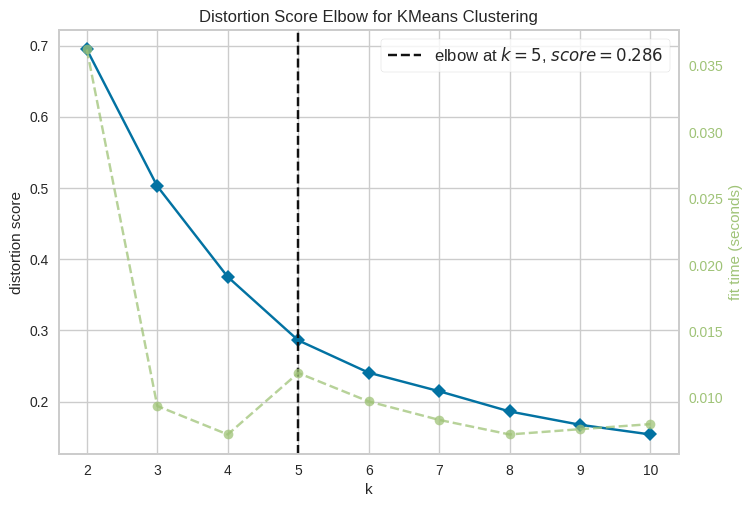

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [15]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

#### <font color = "bisque"> Appliquer Kmeans en utilisant le k optimal

In [16]:
# Initier le modèle
kmeans_model = KMeans(n_clusters = 4, init = 'random', max_iter=500)
# Entrainer le modèle
kmeans_model.fit(x)

KMeans(init='random', max_iter=500, n_clusters=4)

#### <font color = "bisque"> Prédiction la partition

In [17]:
# Prediction de la partition(l'ensemble des classes) de X
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition

array([1, 1, 2, 2, 1, 1, 2, 1, 1, 3, 1, 2, 2, 2, 3, 0, 1, 1, 2, 2, 2, 1,
       2, 1, 1, 2, 2, 2, 2, 1, 2, 2, 2, 1, 1, 1, 2, 0, 2, 2, 2, 3, 2, 1,
       1, 2, 2, 1, 2, 3, 2, 2, 1, 1, 2, 1, 1, 2, 2, 2, 2, 1, 2, 1, 2, 2,
       3, 3, 3, 1, 3, 3, 3, 3, 3, 1, 3, 3, 3, 1, 1, 1, 1, 3, 3, 3, 1, 1,
       1, 3, 3, 3, 1, 1, 1, 1, 3, 1, 3, 1, 1, 1, 3, 1, 1, 1, 3, 1, 3, 3,
       1, 3, 1, 3, 1, 3, 3, 3, 1, 3, 3, 3, 1, 1, 3, 1, 1, 3, 3, 3, 3, 1,
       1, 3, 0, 0, 0, 0, 0, 0, 2, 0, 2, 0, 0, 0, 0, 2, 0, 0, 2, 0, 0, 0,
       2, 0, 0, 0, 0, 2, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 2, 0, 0, 2, 2, 0, 0, 2,
       0], dtype=int32)

In [18]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

,count
1,56
0,53
2,49
3,41


In [19]:
# Diagramme en barre du nombre d'observations dans chaque
import plotly.express as px
fig = px.bar(x = val.index, y = val.values ,color = val.index.astype(str))
fig.show()

#### <font color = "bisque"> Visualiser les classes prédictes par Kmeans

In [20]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 0, y = 1, color = kmeans_partition.astype(str), labels={'0': 'PC1', '1': 'PC2'})
fig.show()

<font color = "bisque">Indice de silhouette value de la partition du Kmeans

In [21]:
# Importer silhouette score
from sklearn.metrics import silhouette_score
# Indice de Silhouette value
sil_kmeans = silhouette_score(x, kmeans_partition)
print(f"Silhouette score : {sil_kmeans }")

Silhouette score : 0.3837887447559465


In [22]:
# Les graines de chaque classes
clusters_names = []
for i in range(4):
  clusters_names.append(list(df.index[kmeans_partition == i]))

In [23]:
# Afficher les graines de la classe 0
print(clusters_names[3])

['Graine10', 'Graine15', 'Graine42', 'Graine50', 'Graine67', 'Graine68', 'Graine69', 'Graine71', 'Graine72', 'Graine73', 'Graine74', 'Graine75', 'Graine77', 'Graine78', 'Graine79', 'Graine84', 'Graine85', 'Graine86', 'Graine90', 'Graine91', 'Graine92', 'Graine97', 'Graine99', 'Graine103', 'Graine107', 'Graine109', 'Graine110', 'Graine112', 'Graine114', 'Graine116', 'Graine117', 'Graine118', 'Graine120', 'Graine121', 'Graine122', 'Graine125', 'Graine128', 'Graine129', 'Graine130', 'Graine131', 'Graine134']


### <font color='gold'> CAH

In [24]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

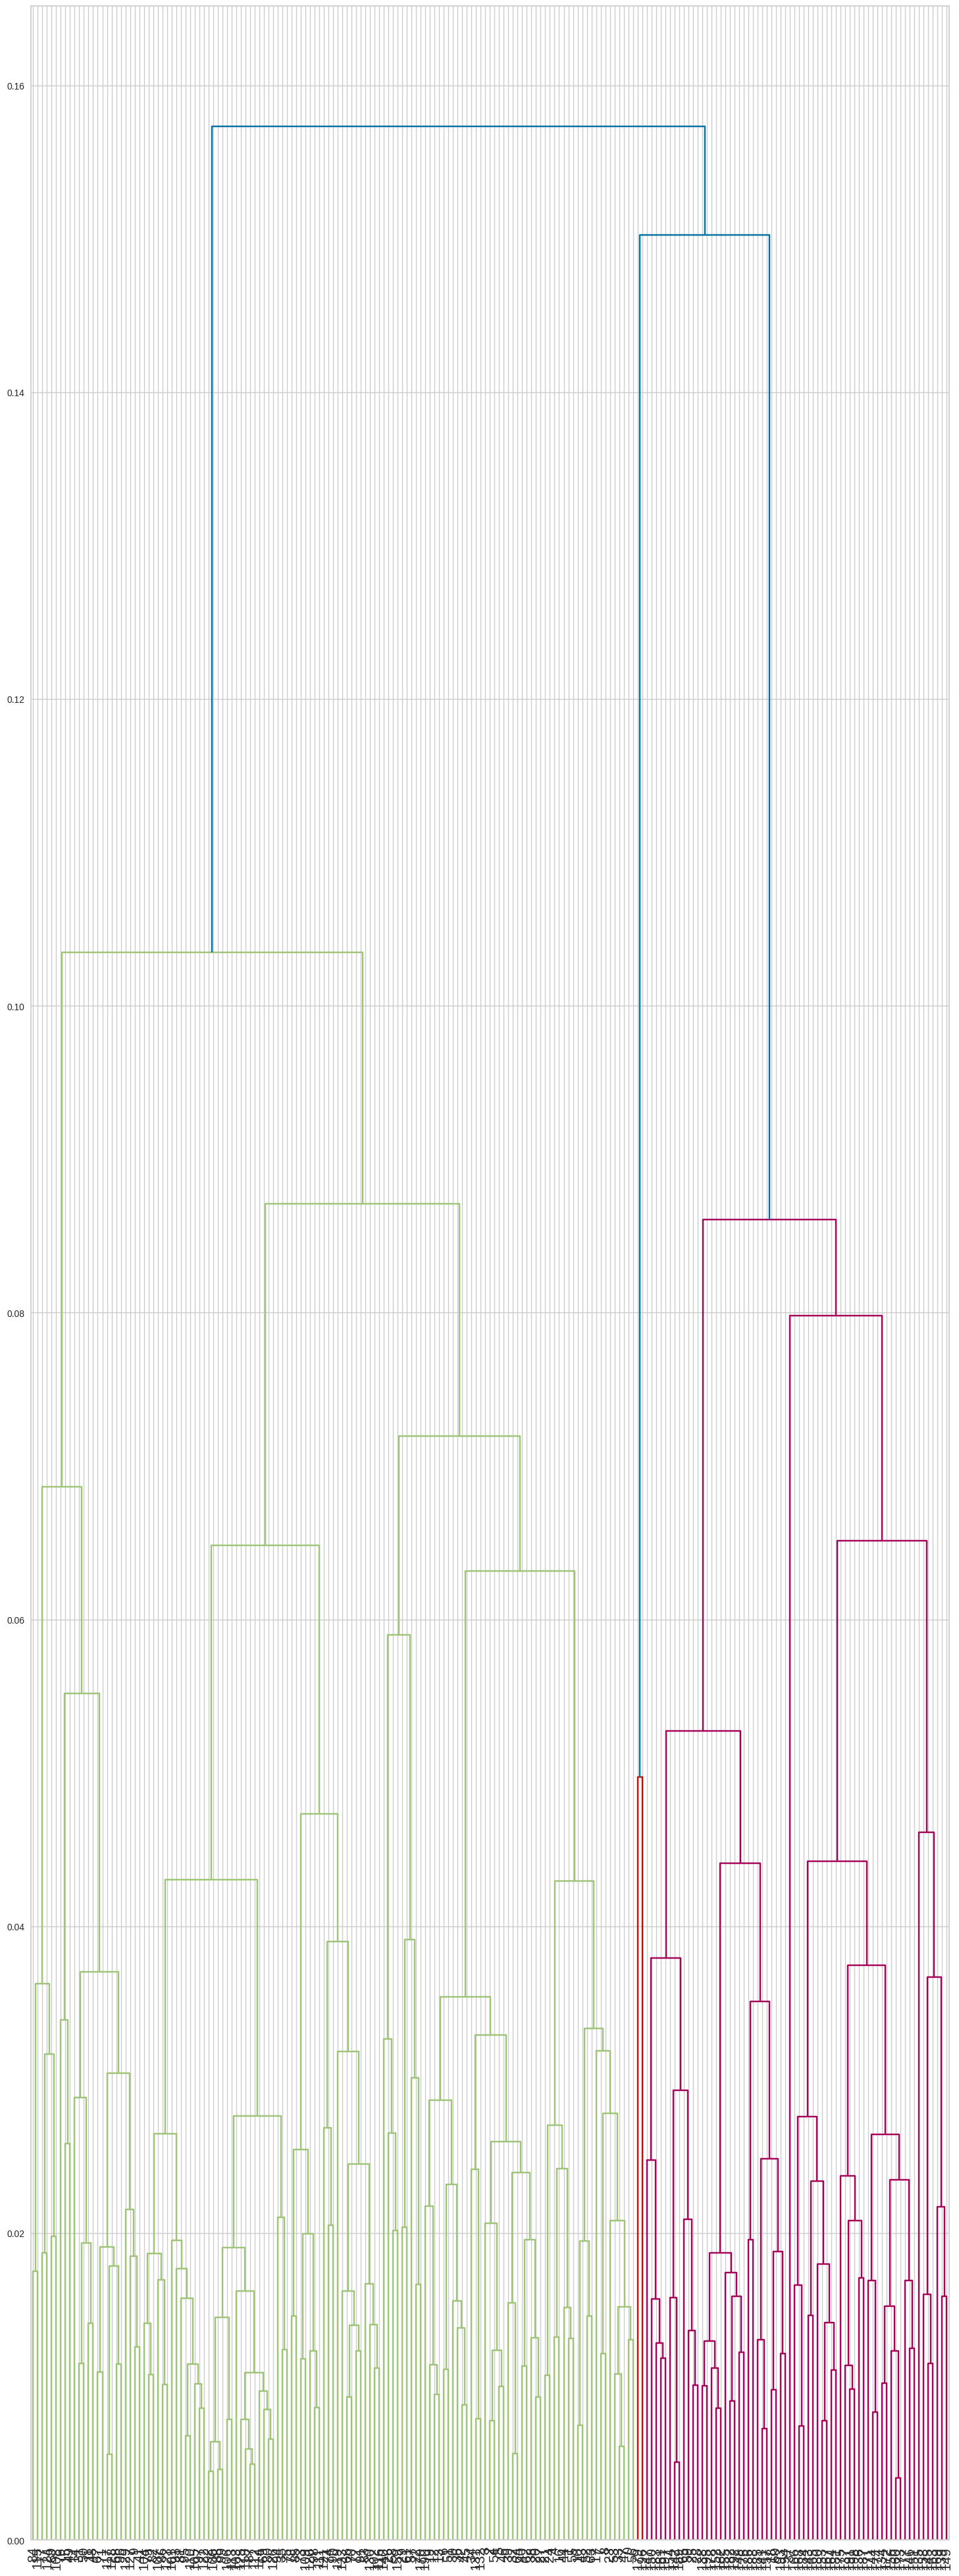

In [25]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(18, 50))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [26]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters =2, linkage = 'average')
# Entrainer le modèle
cah_model.fit(x)

AgglomerativeClustering(linkage='average')

In [27]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[:100]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [28]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(cah_partition).value_counts()
val1

,count
1,131
0,68


In [29]:
# Diagramme en barre des nombres d'observations
fig = px.bar(x = val1.index.astype(str), y = val1.values, color = val1.index.astype(str))
fig.show()

In [30]:
# Visualiser les classes de la CAH sur le plan de l'ACP
fig = px.scatter(df_pca, x = 0, y = 1, color = cah_partition.astype(str), labels={'0': 'PC1', '1': 'PC2'})
fig.show()

In [31]:
# Silhouette score
sil_cah = silhouette_score(x, cah_partition)
print(f"La silhouette score :{sil_cah}")

La silhouette score :0.48377196978779624


In [32]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [33]:
# les indidivus
cluster_names = []
for i in range(2):
  cluster_names.append(list(df.index[cah_partition == i]))

In [34]:
# Les individus de la classe 0
print(cluster_names[0])

['Graine19', 'Graine26', 'Graine29', 'Graine38', 'Graine60', 'Graine61', 'Graine66', 'Graine135', 'Graine136', 'Graine137', 'Graine138', 'Graine139', 'Graine140', 'Graine142', 'Graine143', 'Graine144', 'Graine145', 'Graine146', 'Graine147', 'Graine148', 'Graine149', 'Graine150', 'Graine151', 'Graine152', 'Graine153', 'Graine154', 'Graine155', 'Graine156', 'Graine157', 'Graine158', 'Graine159', 'Graine161', 'Graine162', 'Graine163', 'Graine164', 'Graine165', 'Graine166', 'Graine167', 'Graine168', 'Graine169', 'Graine170', 'Graine172', 'Graine173', 'Graine174', 'Graine175', 'Graine176', 'Graine177', 'Graine178', 'Graine179', 'Graine180', 'Graine181', 'Graine182', 'Graine183', 'Graine184', 'Graine185', 'Graine186', 'Graine187', 'Graine188', 'Graine189', 'Graine190', 'Graine192', 'Graine193', 'Graine194', 'Graine195', 'Graine196', 'Graine197', 'Graine198', 'Graine199']


### <font color = "gold"> Interpréter les classes

Avant de déployer le modèle, il faut savoir **ce que représente chaque classe**, pour afficher un
message compréhensible par l'utilisateur final. On regarde le profil moyen de chaque classe.

In [35]:
# Profil moyen de chaque classe
profil = df.groupby(cah_partition).mean().round(3)
profil

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,11.993,13.306,0.850,5.252,2.869,4.846,5.111
1,16.437,15.265,0.881,5.846,3.471,3.104,5.581


In [36]:
# Noms des classes
noms_classes = {
    0: "petite graine",
    1: "grosse graine",
}

### <font color = "gold"> Préparer le meilleur modèle (CAH) pour le déploiement

`AgglomerativeClustering` n'a pas de méthode `predict()` : il ne sait pas classer une **nouvelle** graine.
On entraîne donc un `NearestCentroid` sur les classes trouvées par la CAH : une nouvelle graine est affectée
à la classe dont le **centroïde est le plus proche**. Ce modèle reproduit la partition de la CAH.

In [37]:
from sklearn.neighbors import NearestCentroid
# Instantier le modèle des centroïdes de la CAH
model = NearestCentroid()
# Entrainer sur les classes trouvées par la CAH
model.fit(x, cah_partition)
# Vérifier que le modèle retrouve bien la partition de la CAH
print("Concordance avec la CAH :", (model.predict(x) == cah_partition).mean())

Concordance avec la CAH : 0.9547738693467337


In [38]:
# Test rapide sur la première graine
graine = scaler.transform(df.iloc[[0]])
print("Classe prédite         :", noms_classes[model.predict(graine)[0]])
print("Classe réelle de la CAH:", noms_classes[cah_partition[0]])

Classe prédite         : grosse graine
Classe réelle de la CAH: grosse graine


### <font color = "gold"> Sauvegarde des modèles (joblib)

On enregistre le normaliseur, l'ACP et le modèle dans le même dossier que les données.
L'application Streamlit `app_wheat.py` les chargera.

In [39]:
import os
# Créer le dossier s'il n'existe pas
os.makedirs('/content/model', exist_ok=True)

In [40]:
import joblib
import sklearn
# Dossier de sauvegarde
# Enregistrer le normaliseur, l'ACP et le modèle
joblib.dump(scaler, '/content/model/scaler_wheat.joblib')
joblib.dump(pca, '/content/model/pca_encoder_wheat.joblib')
joblib.dump(model, '/content/model/model_wheat.joblib')
# Version de scikit-learn à installer aussi pour Streamlit
print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1
